# ICOM5015: Adversarial AI in 4-Player Partnership Domino
**Team Members:** Member 1 (Rules), Member 2 (State Management), Member 3 (Scoring), Member 4 (Interface, Integration & Evaluation)

## 1. AI Approach & Library Justification
- **Game Selected:** 4-Player Partnership Domino (cross-table teams: Team 1 = Players 0 & 2; Team 2 = Players 1 & 3; target = 100 points).
- **AI Techniques Used (Syllabus #3 & #4):** **Averaging Over Clairvoyance** combined with **UCB1 Monte Carlo Simulation**. Pure Minimax is intractable due to $\binom{21}{7}\binom{14}{7} \approx 3.99 \times 10^8$ hidden deal states at Turn 1. Sampling consistent worlds constrained by observed player passes and running tactical Monte Carlo rollouts enables principled decision-making under partial observability.
- **Library Used:** **PettingZoo (`AECEnv`)** — natively models turn-based, multi-agent partial observability (`observe(agent)`) and team rewards without exposing hidden opponent hands.

In [5]:
%pip install matplotlib pettingzoo gymnasium

Note: you may need to restart the kernel to use updated packages.


In [ ]:
from ai_agents import ClairvoyanceMCTSAgent, HeuristicAgent
from game_interface import DominoGameController

demo_agents = [
    ClairvoyanceMCTSAgent(num_worlds=20, rollouts_per_world=8, seed=42, name="ClairvoyanceAI-P0"),
    HeuristicAgent("Heuristic-P1"),
    ClairvoyanceMCTSAgent(num_worlds=20, rollouts_per_world=8, seed=43, name="ClairvoyanceAI-P2"),
    HeuristicAgent("Heuristic-P3"),
]

demo_controller = DominoGameController(
    agents=demo_agents,
    target_score=1,
    reveal_all_hands=True,
    turn_delay_sec=0.0,
)
demo_result = demo_controller.play_match(seed=42)


##############################################################################
STARTING 4-PLAYER PARTNERSHIP DOMINO MATCH
Team 1: P0 (ClairvoyanceAI-P0) & P2 (ClairvoyanceAI-P2)
Team 2: P1 (Heuristic-P1) & P3 (Heuristic-P3)
##############################################################################

*** Beginning Round 1 (Lead: P0 (ClairvoyanceAI-P0)) ***

ROUND 1  |  MATCH SCORE -> Team 1 (P0 & P2): 0 pts  |  Team 2 (P1 & P3): 0 pts  (Target: 100)
------------------------------------------------------------------------------
>>> TURN >>> P0 (ClairvoyanceAI-P0) [Team 1]: 0:[6|6]  1:[3|6]  2:[4|5]  3:[3|5]  4:[3|3]  5:[1|1]  6:[1|6]
             P1 (Heuristic-P1)  [Team 2]: 0:[2|6]  1:[0|2]  2:[1|4]  3:[0|6]  4:[1|2]  5:[3|4]  6:[0|5]
             P2 (ClairvoyanceAI-P2) [Team 1]: 0:[5|6]  1:[2|2]  2:[2|5]  3:[0|0]  4:[2|4]  5:[5|5]  6:[0|3]
             P3 (Heuristic-P3)  [Team 2]: 0:[1|5]  1:[2|3]  2:[0|4]  3:[4|6]  4:[4|4]  5:[1|3]  6:[0|1]
----------------------------------------

In [3]:
from ai_agents import run_full_tournament

# Evaluate across 100 full 100-point matches per scenario (700 matches total)
tournament_results = run_full_tournament(num_matches=100, seed=42)

Matchup                                                        | T1 Win % | Avg Diff | Rounds | Time(s)
------------------------------------------------------------------------------------------------------
(AI + AI) vs (Random + Random)                                 |   85.00% |   +59.88 |   7.12 |   41.68
(AI + AI) vs (Heuristic + Heuristic)                           |   62.00% |   +21.93 |   9.54 |   56.33
(AI + Random) vs (Random + Random) [Weak Partner]              |   80.00% |   +49.18 |   7.22 |   21.96
(AI + Random) vs (Heuristic + Heuristic) [Weak Partner]        |   38.00% |   -12.65 |   9.90 |   29.98
(AI + Heuristic) vs (Heuristic + Heuristic) [Med Partner]      |   74.00% |   +31.56 |  10.65 |   33.11
(AI No-Pass-Infer + AI) vs (Heuristic + Heuristic) [Ablation]  |   65.00% |   +18.21 |  10.32 |   60.11
(AI + AI) vs (AI + AI) [Self-Play Balance]                     |   55.00% |    +7.17 |   7.84 |   91.13


Matplotlib is building the font cache; this may take a moment.


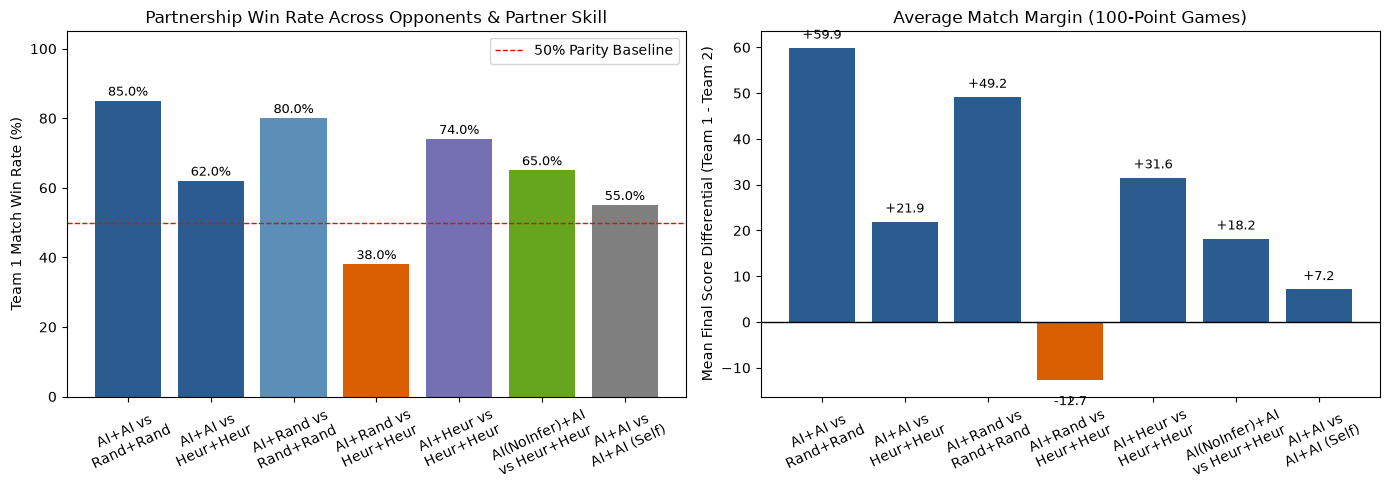

In [4]:
import matplotlib.pyplot as plt

labels = [
    "AI+AI vs\nRand+Rand",
    "AI+AI vs\nHeur+Heur",
    "AI+Rand vs\nRand+Rand",
    "AI+Rand vs\nHeur+Heur",
    "AI+Heur vs\nHeur+Heur",
    "AI(NoInfer)+AI\nvs Heur+Heur",
    "AI+AI vs\nAI+AI (Self)",
]
win_rates = [r["t1_win_rate"] for r in tournament_results]
score_diffs = [r["mean_score_diff"] for r in tournament_results]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Team 1 Win Rate (%)
bars1 = axes[0].bar(labels, win_rates, color=["#2b5c8f", "#2b5c8f", "#5c8fb8", "#d95f02", "#7570b3", "#66a61e", "#7f7f7f"])
axes[0].axhline(50, color="red", linestyle="--", linewidth=1, label="50% Parity Baseline")
axes[0].set_ylim(0, 105)
axes[0].set_ylabel("Team 1 Match Win Rate (%)")
axes[0].set_title("Partnership Win Rate Across Opponents & Partner Skill")
axes[0].tick_params(axis="x", rotation=25)
axes[0].legend()
for bar, val in zip(bars1, win_rates):
    axes[0].text(bar.get_x() + bar.get_width() / 2, val + 1.5, f"{val:.1f}%", ha="center", fontsize=9)

# Plot 2: Mean Score Differential
colors2 = ["#2b5c8f" if d >= 0 else "#d95f02" for d in score_diffs]
bars2 = axes[1].bar(labels, score_diffs, color=colors2)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_ylabel("Mean Final Score Differential (Team 1 - Team 2)")
axes[1].set_title("Average Match Margin (100-Point Games)")
axes[1].tick_params(axis="x", rotation=25)
for bar, val in zip(bars2, score_diffs):
    offset = 2.0 if val >= 0 else -5.5
    axes[1].text(bar.get_x() + bar.get_width() / 2, val + offset, f"{val:+.1f}", ha="center", fontsize=9)

plt.tight_layout()
plt.savefig("domino_tournament_evaluation.png", dpi=300)
plt.show()